# DiabetesCheck AI : dépistage du diabète expliqué (IA hybride)

Mini-projet IA Hybride (ISIS Castres, 5e année) - Sujet 1. Données : Pima Indians Diabetes (768 patientes).

**Plan :**
- **Étape 1 (parties 1 à 6)** : nettoyage des données, valeurs manquantes et modèles de référence (non hybrides)
- **Étape 2 (parties 7 à 15)** : version hybride avec des règles médicales sourcées, et comparaison avec la référence

# Étape 1 : valeurs manquantes et modèles de référence

**Objectif :** remplir les valeurs manquantes de la bonne façon, puis comparer quelques modèles classiques (non hybrides)
pour avoir une référence. Cette référence servira à voir si la version hybride (avec les règles médicales) fait mieux.

## 1. Imports et chargement des données

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
from sklearn.datasets import fetch_openml

# Chargement du jeu Pima depuis OpenML (comme indiqué dans l'énoncé)
data = fetch_openml("diabetes", version=1, as_frame=True)
df = data.frame

# On renomme les colonnes pour qu'elles soient plus lisibles
df.columns = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin",
              "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]
df["Outcome"] = (df["Outcome"] == "tested_positive").astype(int)

print(f"Dimensions : {df.shape}")
df.head()

Dimensions : (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. Règle de qualité : un 0 impossible = valeur manquante

Une glycémie, une pression, un pli cutané, une insuline ou un IMC égal à 0 est impossible chez une patiente vivante :
c'est une valeur qui n'a pas été mesurée. On les remplace par `NaN`. (0 grossesse est possible donc on ne touche pas.)

In [3]:
cols_zero = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[cols_zero] = df[cols_zero].replace(0, np.nan)

# Pourcentage de valeurs manquantes par colonne
print((df.isna().mean() * 100).round(1))

Pregnancies                  0.0
Glucose                      0.7
BloodPressure                4.6
SkinThickness               29.6
Insulin                     48.7
BMI                          1.4
DiabetesPedigreeFunction     0.0
Age                          0.0
Outcome                      0.0
dtype: float64


Insulin (49 %) et SkinThickness (30 %) ont beaucoup de manquants. Si on supprimait les lignes incomplètes on perdrait la
moitié des patientes, donc on va les remplir.

## 3. Séparation train / test

On sépare **avant** de remplir les valeurs manquantes. Sinon le remplissage utiliserait des informations du test
(fuite d'information).

In [4]:
from sklearn.model_selection import train_test_split

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train : {X_train.shape}")
print(f"Test  : {X_test.shape}")

Train : (614, 8)
Test  : (154, 8)


## 4. Comparaison des méthodes pour remplir les valeurs manquantes

On compare 3 méthodes :
- **Médiane** : on remplace par la médiane de la colonne
- **KNN** : on prend la moyenne des 5 patientes qui ressemblent le plus (glycémie, IMC, âge...)
- **MICE** : on prédit la valeur manquante à partir des autres colonnes avec une régression
  (van Buuren & Groothuis-Oudshoorn, 2011)

On met chaque méthode dans un `Pipeline` (standardisation → remplissage → modèle). L'avantage c'est que dans la validation
croisée, le remplissage est réappris à chaque fois seulement sur la partie entraînement, donc pas de fuite.
On utilise la régression logistique pour comparer.

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

imputers = {
    "Médiane": SimpleImputer(strategy="median"),
    "KNN": KNNImputer(n_neighbors=5),
    "MICE": IterativeImputer(max_iter=20, random_state=42),
}

results_imp = []

for name, imputer in imputers.items():
    pipe = Pipeline([
        ("scaler", StandardScaler()),   # avant KNN sinon l'insuline (centaines) écrase l'IMC dans la distance
        ("imputer", imputer),
        ("model", LogisticRegression(max_iter=1000)),
    ])
    auc = cross_val_score(pipe, X_train, y_train, cv=5, scoring="roc_auc")
    results_imp.append({"Méthode": name, "AUC moyenne": auc.mean(), "Écart-type": auc.std()})

df_imp = pd.DataFrame(results_imp).round(3)
df_imp

,Méthode,AUC moyenne,Écart-type
0,Médiane,0.843,0.029
1,KNN,0.842,0.029
2,MICE,0.843,0.030


**Résultat :** les 3 méthodes donnent presque la même AUC (écart de l'ordre de 0.001), alors que l'écart-type est d'environ
0.03. Donc aucune n'est vraiment meilleure. On garde **KNN** car il utilise les autres mesures de la patiente pour remplir.

### Et si on remplissait selon que la patiente est malade ou pas ?

Idée : pour une malade, on met une valeur au hasard dans l'intervalle habituel des malades (Q1-Q3), et pareil pour les
non malades. Le problème c'est que pour une nouvelle patiente **on ne sait pas si elle est malade** (c'est ce qu'on veut
prédire). On teste quand même pour voir ce qui se passe.

In [6]:
# Intervalles Q1-Q3 de chaque colonne, pour les non malades (0) et les malades (1), calculés sur le train
train = X_train.copy()
train["Outcome"] = y_train
q1 = train.groupby("Outcome")[cols_zero].quantile(0.25)
q3 = train.groupby("Outcome")[cols_zero].quantile(0.75)
print("Q1 :\n", q1, "\n\nQ3 :\n", q3)

Q1 :
          Glucose  BloodPressure  SkinThickness  Insulin    BMI
Outcome                                                       
0           94.0           62.0           19.0     64.0  25.90
1          119.0           68.0           27.0    130.0  31.05 

Q3 :
          Glucose  BloodPressure  SkinThickness  Insulin   BMI
Outcome                                                      
0          124.0           78.0           33.0    158.0  35.1
1          168.0           83.0           39.0    231.0  39.1


In [7]:
from sklearn.metrics import roc_auc_score

np.random.seed(42)

# Remplissage selon la classe : on tire une valeur au hasard entre Q1 et Q3 de la classe de la patiente
def remplir_par_classe(X_part, y_part):
    X_part = X_part.copy()
    for col in cols_zero:
        for classe in [0, 1]:
            manque = X_part[col].isna() & (y_part == classe)
            X_part.loc[manque, col] = np.random.uniform(q1.loc[classe, col], q3.loc[classe, col], manque.sum())
    return X_part

X_train_classe = remplir_par_classe(X_train, y_train)

# Cas 1 (triche) : on remplit aussi le test avec sa vraie réponse
X_test_triche = remplir_par_classe(X_test, y_test)

# Cas 2 (honnête) : on ne connaît pas la réponse du test, donc on le remplit avec la médiane du train
X_test_honnete = X_test.fillna(X_train.median())

scaler = StandardScaler().fit(X_train_classe)
model = LogisticRegression(max_iter=1000).fit(scaler.transform(X_train_classe), y_train)

auc_triche = roc_auc_score(y_test, model.predict_proba(scaler.transform(X_test_triche))[:, 1])
auc_honnete = roc_auc_score(y_test, model.predict_proba(scaler.transform(X_test_honnete))[:, 1])

print(f"AUC test - remplissage par classe (triche)  : {auc_triche:.3f}")
print(f"AUC test - remplissage par classe (honnête) : {auc_honnete:.3f}")

AUC test - remplissage par classe (triche)  : 0.832
AUC test - remplissage par classe (honnête) : 0.788


**Conclusion :** la version triche a l'air meilleure (environ 0.83), mais c'est faux : le modèle a appris que « une
insuline remplie avec une valeur de malade = malade ». On a écrit la réponse dans les données. Dans la version honnête
(la seule possible en vrai), le score retombe vers 0.79, c'est même moins bien que KNN. Donc on **n'utilise pas** cette
méthode : c'est une fuite d'information.

## 5. Comparaison des modèles de référence

On garde 3 modèles :
- **Régression logistique** (demandée dans l'énoncé, simple et explicable)
- **Random Forest**
- **XGBoost** (gradient boosting, demandé dans l'énoncé)

Pour chaque modèle : validation croisée sur le train (AUC) puis évaluation sur le test.

In [8]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import f1_score, recall_score, accuracy_score

models = {
    "Régression logistique": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42),
}

results = []

for name, model in models.items():
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("imputer", KNNImputer(n_neighbors=5)),
        ("model", model),
    ])

    # Validation croisée sur le train
    auc_cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring="roc_auc").mean()

    # Entraînement sur tout le train et prédiction sur le test
    pipe.fit(X_train, y_train)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    y_pred = pipe.predict(X_test)

    results.append({
        "Modèle": name,
        "AUC (CV)": auc_cv,
        "AUC (test)": roc_auc_score(y_test, y_proba),
        "F1": f1_score(y_test, y_pred),
        "Rappel": recall_score(y_test, y_pred),
        "Accuracy": accuracy_score(y_test, y_pred),
    })

df_results = pd.DataFrame(results).round(3)
df_results

,Modèle,AUC (CV),AUC (test),F1,Rappel,Accuracy
0,Régression logistique,0.842,0.814,0.531,0.481,0.701
1,Random Forest,0.836,0.812,0.588,0.556,0.727
2,XGBoost,0.819,0.832,0.692,0.685,0.786


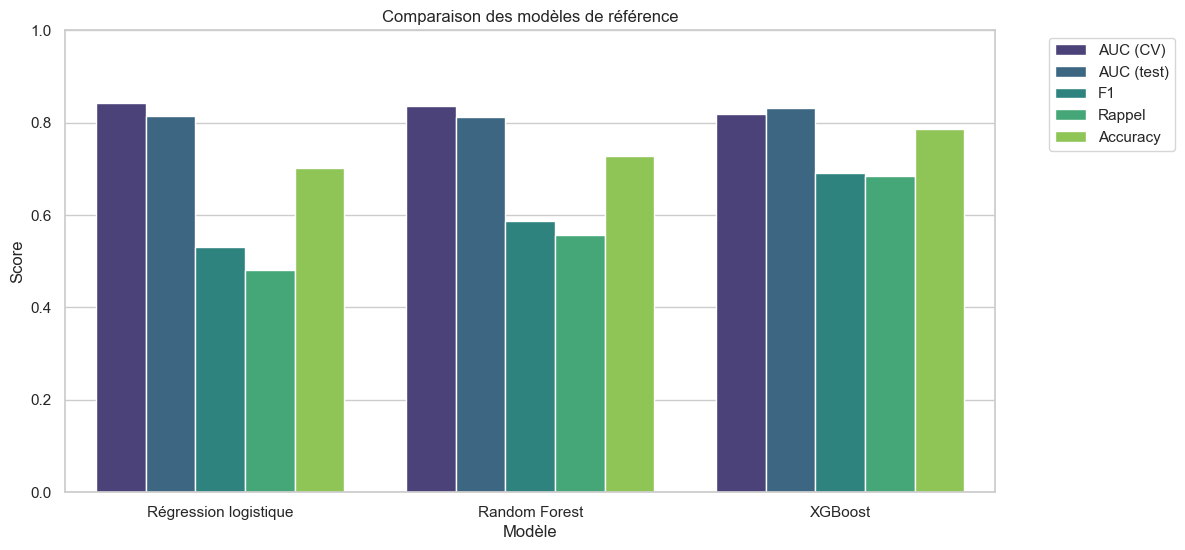

In [9]:
df_plot = df_results.melt(id_vars="Modèle", var_name="Métrique", value_name="Score")

plt.figure(figsize=(12, 6))
sns.barplot(x="Modèle", y="Score", hue="Métrique", data=df_plot, palette="viridis")
plt.title("Comparaison des modèles de référence")
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()

### Ce qu'on conclut de cette comparaison

**Rappel des métriques :**
- **AUC** : capacité à mettre les malades au-dessus des non malades (1 = parfait, 0.5 = hasard)
- **Rappel** : sur 10 malades, combien on en détecte (le plus important pour un dépistage)
- **F1** : compromis entre rappel et précision (éviter les fausses alertes)

| Modèle | AUC (CV) | AUC (test) | Rappel (test) |
|---|---|---|---|
| Régression logistique | **0.842** | 0.814 | 0.48 |
| Random Forest | 0.836 | 0.812 | 0.56 |
| XGBoost | 0.819 | **0.832** | **0.69** |

**1. En validation croisée, la régression logistique est la meilleure.** La validation croisée est la mesure la plus
fiable car elle teste le modèle 5 fois sur des patientes différentes (614 patientes au total).

**2. Sur le test, c'est XGBoost qui est le meilleur.** Le classement s'inverse ! Ça vient du fait que le test ne contient
que 154 patientes : quelques patientes en plus ou en moins bien classées suffisent à changer l'ordre. Les écarts d'AUC
(0.02 environ) sont plus petits que l'incertitude (environ ± 0.03), donc **les 3 modèles sont en réalité au même niveau**.

**3. Le rappel est faible pour tous les modèles (entre 48 % et 69 %).** Ça veut dire qu'on rate entre 3 et 5 malades sur 10.
C'est parce qu'on utilise le seuil par défaut de 0.5 : une patiente est classée malade seulement si le risque dépasse 50 %.
Pour un dépistage, on pourra **baisser ce seuil** plus tard (par exemple 0.3) pour détecter plus de malades.

**Choix :** comme les modèles sont au même niveau, on garde les 2 modèles demandés par l'énoncé comme **références** :
- la **régression logistique** : la meilleure en validation croisée et la plus facile à expliquer à un médecin
- **XGBoost** : le meilleur sur le test et le meilleur rappel

Random Forest n'apporte rien de plus, on ne le garde pas pour la suite.

### SMOTE ou baisser le seuil ?

En dépistage, rater une malade (faux négatif) est plus grave qu'envoyer chez le médecin quelqu'un qui n'est pas malade
(faux positif). On veut donc un bon **rappel**. Dans notre premier notebook on utilisait SMOTE pour ça.
Ici on compare SMOTE avec une autre solution : **baisser le seuil de décision** (dire « malade » dès que le risque dépasse 0.3 au lieu de 0.5).

In [10]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import confusion_matrix, brier_score_loss

# XGBoost sans SMOTE
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("imputer", KNNImputer(n_neighbors=5)),
    ("model", XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42)),
])
pipe.fit(X_train, y_train)
proba = pipe.predict_proba(X_test)[:, 1]

# XGBoost avec SMOTE (appliqué seulement sur le train grâce au pipeline)
pipe_smote = ImbPipeline([
    ("scaler", StandardScaler()),
    ("imputer", KNNImputer(n_neighbors=5)),
    ("smote", SMOTE(random_state=42)),
    ("model", XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42)),
])
pipe_smote.fit(X_train, y_train)
proba_smote = pipe_smote.predict_proba(X_test)[:, 1]

results_seuil = []

for nom, p, seuil in [("Sans SMOTE, seuil 0.5", proba, 0.5),
                      ("SMOTE, seuil 0.5", proba_smote, 0.5),
                      ("Sans SMOTE, seuil 0.4", proba, 0.4),
                      ("Sans SMOTE, seuil 0.3", proba, 0.3)]:
    tn, fp, fn, tp = confusion_matrix(y_test, p >= seuil).ravel()
    results_seuil.append({
        "Version": nom,
        "Rappel": tp / (tp + fn),
        "Malades ratées (FN)": fn,
        "Fausses alertes (FP)": fp,
        "Brier": brier_score_loss(y_test, p),
    })

pd.DataFrame(results_seuil).round(3)

,Version,Rappel,Malades ratées (FN),Fausses alertes (FP),Brier
0,"Sans SMOTE, seuil 0.5",0.685,17,16,0.164
1,"SMOTE, seuil 0.5",0.741,14,24,0.172
2,"Sans SMOTE, seuil 0.4",0.722,15,23,0.164
3,"Sans SMOTE, seuil 0.3",0.833,9,27,0.164


**Conclusion :** baisser le seuil à 0.3 fait mieux que SMOTE : on rate 9 malades au lieu de 14, pour seulement
3 fausses alertes en plus. En plus, SMOTE abîme les probabilités (le Brier monte de 0.164 à 0.172), alors que le seuil
ne les change pas. On n'utilise donc **pas SMOTE**, on baisse plutôt le seuil (on vérifie ce choix avec la matrice de confusion plus bas).

### Performance par tranche d'âge

Le jeu contient **uniquement des femmes Pima de 21 ans et plus** : on ne peut donc pas comparer hommes et femmes.
Par contre on peut regarder si le jeu est déséquilibré selon l'âge, et si le modèle marche aussi bien pour toutes les tranches d'âge.

In [11]:
# On découpe l'âge en 3 tranches
tranches = pd.cut(X_test["Age"], bins=[20, 30, 45, 100], labels=["21-30 ans", "31-45 ans", "46 ans et +"])

# On réentraîne XGBoost (sans SMOTE) pour avoir ses probabilités sur le test
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("imputer", KNNImputer(n_neighbors=5)),
    ("model", XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42)),
])
pipe.fit(X_train, y_train)
proba = pipe.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

results_age = []

for tranche in tranches.cat.categories:
    masque = (tranches == tranche).values
    results_age.append({
        "Tranche d'âge": tranche,
        "Nb patientes": masque.sum(),
        "% de malades": y_test[masque].mean() * 100,
        "AUC": roc_auc_score(y_test[masque], proba[masque]),
        "Rappel": recall_score(y_test[masque], pred[masque]),
    })

pd.DataFrame(results_age).round(2)

,Tranche d'âge,Nb patientes,% de malades,AUC,Rappel
0,21-30 ans,89,20.22,0.77,0.44
1,31-45 ans,40,65.00,0.76,0.77
2,46 ans et +,25,40.00,0.85,0.90


**Conclusion :**
- Le jeu est déséquilibré selon l'âge : 58 % des patientes du test ont entre 21 et 30 ans, et seulement 20 % d'entre elles
  sont malades (contre 65 % chez les 31-45 ans).
- Le modèle détecte mal les jeunes malades : rappel de **0.44** chez les 21-30 ans (8 malades détectées sur 18), contre
  0.77 et 0.90 pour les tranches plus âgées. Le modèle a appris que « jeune = rarement malade » et sous-estime leur risque.
  C'est un **biais selon l'âge**.
- Les tranches sont petites (25 patientes chez les 46 ans et +), donc ces chiffres sont à prendre avec prudence.
- Piste : les règles médicales (ex : glycémie ≥ 140) ne dépendent pas de l'âge et pourraient aider à repérer ces jeunes
  malades. On le vérifiera à l'étape 2.
- Rappel : le jeu ne contient que des **femmes Pima de 21 ans et plus**, on ne peut pas généraliser ces résultats à
  d'autres populations (hommes, autres origines, moins de 21 ans).

### Quelles variables comptent le plus ? (coefficients de la régression logistique)

Chaque variable a un coefficient : positif = augmente le risque, négatif = le diminue. Comme les données sont
standardisées, on peut comparer les coefficients entre eux : plus il est grand, plus la variable compte.

D:\flutter_temp\ipykernel_320\3688249487.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Coefficient", y="Variable", data=coefs, palette="coolwarm")


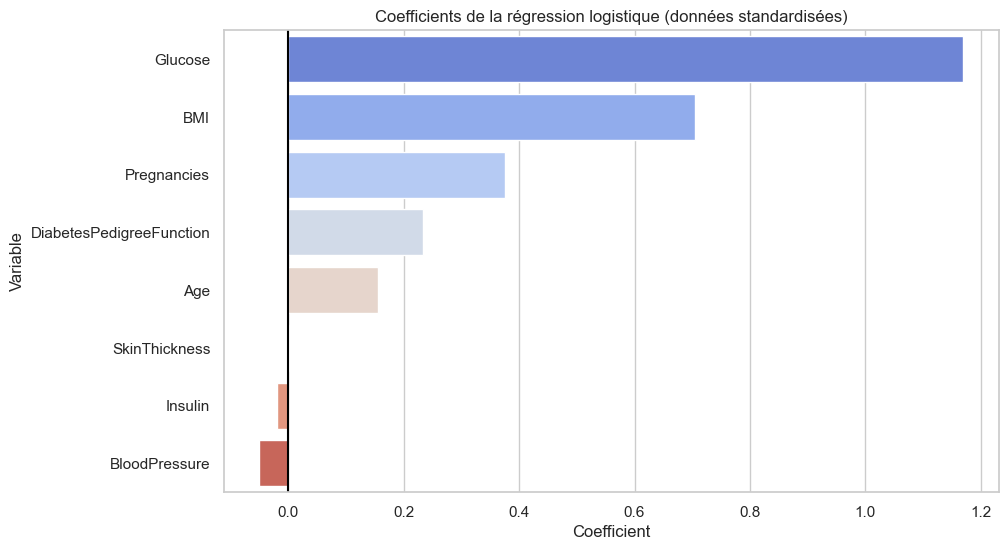

,Variable,Coefficient
1,Glucose,1.169
5,BMI,0.704
0,Pregnancies,0.376
6,DiabetesPedigreeFunction,0.233
7,Age,0.156
3,SkinThickness,0.001
4,Insulin,-0.019
2,BloodPressure,-0.051


In [12]:
# On entraîne la régression logistique sur tout le train
pipe_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("imputer", KNNImputer(n_neighbors=5)),
    ("model", LogisticRegression(max_iter=1000)),
])
pipe_lr.fit(X_train, y_train)

# On récupère les coefficients du modèle
coefs = pd.DataFrame({
    "Variable": X_train.columns,
    "Coefficient": pipe_lr.named_steps["model"].coef_[0],
}).sort_values(by="Coefficient", ascending=False)

# Visualisation
plt.figure(figsize=(10, 6))
sns.barplot(x="Coefficient", y="Variable", data=coefs, palette="coolwarm")
plt.title("Coefficients de la régression logistique (données standardisées)")
plt.axvline(0, color="black")
plt.show()

coefs.round(3)

**Conclusion :**
- **Glucose** (1.17) et **BMI** (0.70) sont de loin les variables les plus importantes : +30 mg/dL de glycémie multiplie
  la cote de risque par 3.2, et +7 kg/m² d'IMC la multiplie par 2. C'est cohérent avec la médecine.
- **Insulin, SkinThickness et BloodPressure** ont un coefficient proche de 0 : le modèle ne les utilise presque pas.
  Ça explique pourquoi la méthode de remplissage des valeurs manquantes ne changeait rien (ce sont justement les
  variables qui manquent le plus).
- **Age** compte peu (0.16), sûrement parce qu'il est lié au nombre de grossesses, qui « prend » une partie de son effet.
- Les variables importantes pour le modèle sont les mêmes que celles des règles médicales (glycémie, IMC) : le modèle
  et les recommandations sont d'accord.

### Matrice de confusion : seuil 0.5 vs seuil 0.3

On regarde concrètement combien de malades sont ratées (faux négatifs) et combien de fausses alertes on donne
(faux positifs), avec le seuil par défaut (0.5) et avec un seuil plus bas (0.3) adapté au dépistage.

Seuil 0.5 : 37 malades détectées sur 54, 17 ratées, 16 fausses alertes
Seuil 0.3 : 45 malades détectées sur 54, 9 ratées, 27 fausses alertes


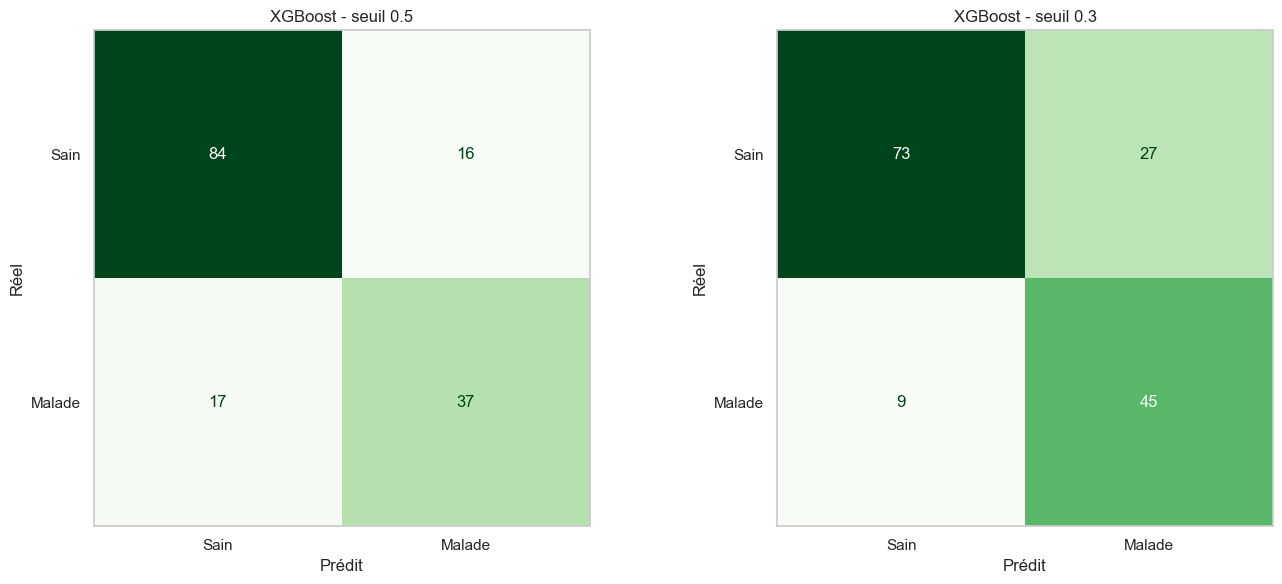

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# On utilise les probabilités de XGBoost calculées dans la partie "Performance par tranche d'âge" (variable proba)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, seuil in zip(axes, [0.5, 0.3]):
    y_pred_seuil = (proba >= seuil).astype(int)
    cm = confusion_matrix(y_test, y_pred_seuil)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Sain", "Malade"])
    disp.plot(cmap="Greens", values_format="d", ax=ax, colorbar=False)
    ax.set_title(f"XGBoost - seuil {seuil}")
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")
    ax.grid(False)

    tn, fp, fn, tp = cm.ravel()
    print(f"Seuil {seuil} : {tp} malades détectées sur {tp + fn}, {fn} ratées, {fp} fausses alertes")

plt.tight_layout()
plt.show()

**Conclusion :**
- Avec le seuil **0.5** : on détecte 37 malades sur 54, on en **rate 17** (presque 1 sur 3), et on donne 16 fausses alertes.
- Avec le seuil **0.3** : on détecte 45 malades sur 54, on en **rate seulement 9** (1 sur 6), mais on donne 27 fausses alertes.
- En baissant le seuil, on récupère **8 malades** en échange de **11 fausses alertes** en plus. Pour un dépistage c'est un
  bon échange : une fausse alerte = un rendez-vous chez le médecin en plus, alors qu'une malade ratée = un diabète non soigné.
- Pour la suite on utilisera donc un **seuil de 0.3** pour la décision « à risque / pas à risque ».

## 6. Conclusion de l'étape 1

- **Valeurs manquantes :** médiane, KNN et MICE donnent le même résultat (AUC ≈ 0.84). On garde KNN. Le remplissage
  selon la classe (malade / pas malade) est une fuite d'information, on ne l'utilise pas.
- **Modèles :** les 3 modèles ont des AUC proches (0.81-0.84) : ils sont au même niveau. On garde la
  **régression logistique** (la plus explicable) et **XGBoost** (meilleur rappel) comme références.
- **SMOTE :** on ne l'utilise pas. Pour détecter plus de malades, il vaut mieux **baisser le seuil à 0.3** : on rate
  9 malades au lieu de 14 avec SMOTE, et les probabilités restent fiables.
- **Seuil 0.3 :** on passe de 17 à 9 malades ratées, pour 11 fausses alertes en plus. C'est un bon échange pour un dépistage.
- **Âge :** le modèle rate plus d'une jeune malade sur deux (rappel 0.44 chez les 21-30 ans) : biais à corriger dans
  la version hybride.
- **Variables importantes :** glycémie et IMC dominent, insuline / pli cutané / pression ne servent presque pas.
- **Limite :** le jeu ne contient que des femmes Pima de 21 ans et plus, on ne peut pas généraliser à d'autres populations.
- **Prochaine étape :** ajouter les **règles médicales** (version hybride) et comparer avec ces résultats.

# Étape 2 : version hybride avec des règles médicales

**Objectif :** ajouter des connaissances médicales au modèle, de 2 façons :
1. **Règles en entrée** : on crée de nouvelles colonnes à partir de seuils médicaux (ex : « obèse = IMC ≥ 30 »)
2. **Règles en sortie** : après la prédiction du modèle, des règles peuvent corriger la décision, en indiquant leur source

On réutilise les données de l'étape 1 (`X_train`, `X_test`, même découpage), donc pas besoin de les recharger.
Comme décidé à l'étape 1, on utilise un **seuil de décision de 0.3** (dépistage).

## 7. Les règles médicales et leurs sources

**Attention aux unités :** dans le jeu Pima, `Glucose` est la glycémie **2 h après une charge de 75 g de glucose** (HGPO),
en mg/dL. Les seuils de l'ADA pour l'HGPO s'appliquent donc directement (ce ne sont pas les seuils à jeun : 100 / 126).

| Règle | Condition | Signification | Source |
|---|---|---|---|
| R1 | Glucose ≥ 200 | diabète | ADA, *Standards of Care in Diabetes 2024*, section 2 |
| R2 | 140 ≤ Glucose < 200 | intolérance au glucose (prédiabète) | ADA 2024 section 2 ; OMS 2006 |
| R3 | BMI ≥ 30 | obésité | OMS, classification de l'IMC |
| R4 | BMI ≥ 25 et Age ≥ 35 | dépistage recommandé (surpoids + âge) | USPSTF 2021, *Screening for Prediabetes and Type 2 Diabetes* |
| R5 | BloodPressure ≥ 90 | hypertension (pression diastolique) | ESC/ESH 2018 ; facteur de risque listé par l'ADA |
| R6 | Glucose < 140 et BMI < 25 et Age < 35 | aucun facteur de risque → risque faible | **règle construite par nous** (voir ci-dessous) |

**Attention : R6 n'est pas une recommandation officielle.** On l'a construite nous-mêmes en combinant les seuils des
autres sources : glycémie normale (< 140, ADA), pas de surpoids (IMC < 25, OMS) et moins de 35 ans (âge de début du
dépistage, USPSTF). Les autres règles (R1 à R5) viennent directement des recommandations.

On regarde d'abord combien de patientes sont concernées par chaque règle, et leur taux de diabète.

In [14]:
def ajouter_regles(X):
    X = X.copy()
    # Une valeur manquante (NaN) donne False dans les comparaisons : la règle ne se déclenche pas
    X["R1_diabete"] = (X["Glucose"] >= 200).astype(int)
    X["R2_intolerance"] = ((X["Glucose"] >= 140) & (X["Glucose"] < 200)).astype(int)
    X["R3_obesite"] = (X["BMI"] >= 30).astype(int)
    X["R4_depistage"] = ((X["BMI"] >= 25) & (X["Age"] >= 35)).astype(int)
    X["R5_hypertension"] = (X["BloodPressure"] >= 90).astype(int)
    X["R6_faible_risque"] = ((X["Glucose"] < 140) & (X["BMI"] < 25) & (X["Age"] < 35)).astype(int)
    return X

regles = ["R1_diabete", "R2_intolerance", "R3_obesite", "R4_depistage", "R5_hypertension", "R6_faible_risque"]

# Statistiques sur le train uniquement
train_regles = ajouter_regles(X_train)
stats = []

for r in regles:
    active = train_regles[r] == 1

    # Si la règle ne se déclenche jamais, on ne peut pas calculer de taux
    if active.sum() > 0:
        taux_si_vraie = y_train[active].mean()
    else:
        taux_si_vraie = np.nan

    stats.append({
        "Règle": r,
        "Nb patientes": active.sum(),
        "Taux diabète si règle vraie": taux_si_vraie,
        "Taux diabète sinon": y_train[~active].mean(),
    })

df_stats = pd.DataFrame(stats).round(2)
df_stats

,Règle,Nb patientes,Taux diabète si règle vraie,Taux diabète sinon
0,R1_diabete,0,NaN,0.35
1,R2_intolerance,156,0.71,0.23
2,R3_obesite,379,0.46,0.17
3,R4_depistage,202,0.54,0.25
4,R5_hypertension,44,0.50,0.34
5,R6_faible_risque,59,0.02,0.38


**Observations :**
- **R1 ne se déclenche jamais** : dans le jeu Pima la glycémie maximum est 199. Les patientes déjà diabétiques au moment de
  la mesure n'ont sans doute pas été incluses (l'étude prédit l'apparition du diabète dans les 5 ans). On garde quand même la
  règle : elle servira pour les cas hors distribution (une nouvelle patiente avec une glycémie de 250).
- **R2 (intolérance au glucose)** : environ 2/3 des patientes concernées sont diabétiques, contre environ 1/4 sinon.
- **R6 (aucun facteur de risque)** : presque aucune patiente concernée n'est diabétique, c'est une règle très fiable.
- **R5 (hypertension)** : peu de patientes (44) et peu de différence (50 % contre 34 %) : c'est la
  règle la plus faible. C'est cohérent avec l'étape 1, où la pression avait un coefficient proche de 0.

## 8. Référence (rappel de l'étape 1)

On recalcule les 2 modèles de référence (régression logistique et XGBoost, **sans règles**), mais cette fois avec le
**seuil de 0.3** choisi à l'étape 1. C'est à ces résultats qu'on comparera les versions hybrides.

Pour ne pas réécrire les mêmes lignes à chaque fois, on crée 2 petites fonctions :
- `creer_pipeline` : standardisation → remplissage KNN → modèle (comme à l'étape 1)
- `evaluer` : calcule l'AUC, le F1, le rappel et l'accuracy avec le seuil 0.3

In [15]:
def creer_pipeline(model):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("imputer", KNNImputer(n_neighbors=5)),
        ("model", model),
    ])


def evaluer(modele, version, y_vrai, y_proba, seuil=0.3):
    y_pred = (y_proba >= seuil).astype(int)
    return {
        "Modèle": modele,
        "Version": version,
        "AUC": roc_auc_score(y_vrai, y_proba),
        "F1": f1_score(y_vrai, y_pred),
        "Rappel": recall_score(y_vrai, y_pred),
        "Accuracy": accuracy_score(y_vrai, y_pred),
    }


models = {
    "Régression logistique": LogisticRegression(max_iter=1000),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42),
}

proba_ref = {}
results = []

for name, model in models.items():
    pipe = creer_pipeline(model)
    pipe.fit(X_train, y_train)
    proba_ref[name] = pipe.predict_proba(X_test)[:, 1]
    results.append(evaluer(name, "1. Référence", y_test, proba_ref[name]))

pd.DataFrame(results).round(3)

,Modèle,Version,AUC,F1,Rappel,Accuracy
0,Régression logistique,1. Référence,0.814,0.661,0.778,0.721
1,XGBoost,1. Référence,0.832,0.714,0.833,0.766


**Conclusion :** l'AUC ne change pas par rapport à l'étape 1 (0.814 et 0.832), c'est normal car l'AUC ne dépend pas
du seuil. Par contre le **rappel monte beaucoup** grâce au seuil 0.3 : 0.48 → 0.78 pour la régression logistique et
0.69 → 0.83 pour XGBoost. C'est notre référence pour la suite.

## 9. Hybride n°1 : règles en entrée

On ajoute les colonnes des règles aux 8 variables de départ. Le modèle peut alors utiliser directement des seuils médicaux.

In [16]:
X_train_r = ajouter_regles(X_train)
X_test_r = ajouter_regles(X_test)

proba_entree = {}

for name, model in models.items():
    pipe = creer_pipeline(model)
    pipe.fit(X_train_r, y_train)
    proba_entree[name] = pipe.predict_proba(X_test_r)[:, 1]
    results.append(evaluer(name, "2. Règles en entrée", y_test, proba_entree[name]))

pd.DataFrame(results).round(3)

,Modèle,Version,AUC,F1,Rappel,Accuracy
0,Régression logistique,1. Référence,0.814,0.661,0.778,0.721
1,XGBoost,1. Référence,0.832,0.714,0.833,0.766
2,Régression logistique,2. Règles en entrée,0.823,0.692,0.833,0.740
3,XGBoost,2. Règles en entrée,0.818,0.710,0.815,0.766


**Conclusion :**
- **Régression logistique** : les règles aident un peu (AUC 0.814 → 0.823, rappel 0.78 → 0.83, donc 3 malades détectées
  en plus). La régression logistique ne sait faire que des relations « en ligne droite », les règles lui donnent des seuils
  (des « marches ») qu'elle ne pouvait pas trouver toute seule.
- **XGBoost** : les règles n'aident pas (AUC 0.832 → 0.818). Les arbres de décision fonctionnent déjà avec des seuils
  (« si glycémie > 140 alors... »), donc les règles ne leur apprennent rien de nouveau.

## 10. Hybride n°2 : règles en sortie

Après la prédiction du modèle, on applique 2 règles qui **corrigent** la probabilité :
- **R1** (Glucose ≥ 200, critère ADA de diabète) → on force un risque d'au moins 0.9
- **R6** (aucun facteur de risque) → on limite le risque à 0.1 maximum

Les valeurs 0.9 et 0.1 ont été **choisies par nous** :
- 0.9 car R1 est un critère de **diagnostic** du diabète (ADA) : le risque doit être très élevé, quoi que dise le modèle
- 0.1 car sur le train, seulement 2 % des patientes concernées par R6 sont diabétiques (1 sur 59)

Pour chaque patiente on garde aussi **la source de la décision** : le modèle, ou la règle qui a corrigé.

In [17]:
def regles_sortie(X, proba):
    proba = proba.copy()

    for i in range(len(X)):
        glucose = X["Glucose"].iloc[i]
        bmi = X["BMI"].iloc[i]
        age = X["Age"].iloc[i]

        # R1 : glycémie >= 200 -> diabète (ADA 2024), le risque doit être au moins 0.9
        if glucose >= 200:
            proba[i] = max(proba[i], 0.9)

        # R6 : aucun facteur de risque -> le risque ne doit pas dépasser 0.1
        if glucose < 140 and bmi < 25 and age < 35:
            proba[i] = min(proba[i], 0.1)

    return proba


def source_decision(patiente):
    # Renvoie qui a pris la décision pour une patiente : une règle ou le modèle
    if patiente["Glucose"] >= 200:
        return "R1 : glycémie 2h >= 200 mg/dL (ADA 2024)"
    if patiente["Glucose"] < 140 and patiente["BMI"] < 25 and patiente["Age"] < 35:
        return "R6 : aucun facteur de risque (règle construite par nous)"
    return "Modèle"


proba_sortie = {}
proba_complet = {}

for name in models:
    # Hybride n°2 : référence + règles en sortie
    proba_sortie[name] = regles_sortie(X_test, proba_ref[name])
    results.append(evaluer(name, "3. Règles en sortie", y_test, proba_sortie[name]))

    # Hybride complet : règles en entrée + règles en sortie
    proba_complet[name] = regles_sortie(X_test, proba_entree[name])
    results.append(evaluer(name, "4. Complet (entrée + sortie)", y_test, proba_complet[name]))

# Source de la décision pour chaque patiente du test
sources = []
for i in range(len(X_test)):
    sources.append(source_decision(X_test.iloc[i]))

print(pd.Series(sources).value_counts())

Modèle                                                      141
R6 : aucun facteur de risque (règle construite par nous)     13
Name: count, dtype: int64


**Conclusion :** sur les 154 patientes du test, la décision vient du **modèle** pour 141 patientes et de la
**règle R6** pour 13 patientes. R1 ne s'applique à personne (aucune glycémie ≥ 200 dans le jeu).

## 11. Comparaison : référence vs versions hybrides (ablation)

C'est notre **ablation** : on enlève ou ajoute une brique (règles en entrée, règles en sortie) et on regarde ce qui change.

In [18]:
df_results = pd.DataFrame(results).round(3)
df_results

,Modèle,Version,AUC,F1,Rappel,Accuracy
0,Régression logistique,1. Référence,0.814,0.661,0.778,0.721
1,XGBoost,1. Référence,0.832,0.714,0.833,0.766
2,Régression logistique,2. Règles en entrée,0.823,0.692,0.833,0.740
3,XGBoost,2. Règles en entrée,0.818,0.710,0.815,0.766
4,Régression logistique,3. Règles en sortie,0.814,0.661,0.778,0.721
5,Régression logistique,4. Complet (entrée + sortie),0.823,0.692,0.833,0.740
6,XGBoost,3. Règles en sortie,0.832,0.714,0.833,0.766
7,XGBoost,4. Complet (entrée + sortie),0.818,0.710,0.815,0.766


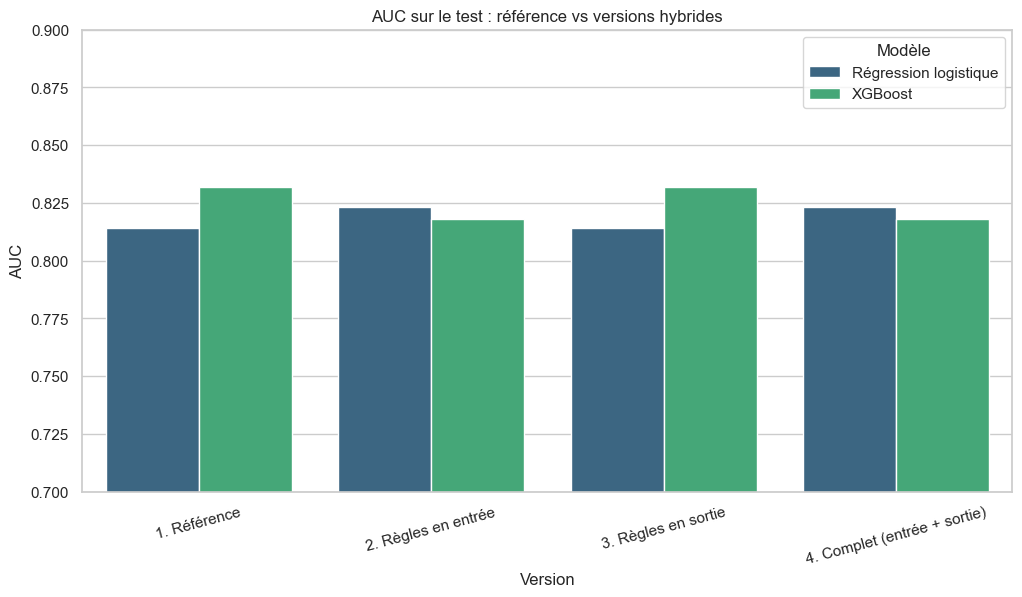

In [19]:
plt.figure(figsize=(12, 6))
sns.barplot(x="Version", y="AUC", hue="Modèle", data=df_results, palette="viridis")
plt.title("AUC sur le test : référence vs versions hybrides")
plt.ylim(0.7, 0.9)
plt.xticks(rotation=15)
plt.show()

**Conclusion de l'ablation :**
- Les versions **3 (règles en sortie)** et **1 (référence)** ont exactement les mêmes scores, pareil pour **4 (complet)**
  et **2 (règles en entrée)**. Donc sur ce test, la brique « règles en sortie » ne change rien : les 13 patientes R6
  avaient déjà un risque faible, et R1 ne se déclenche jamais.
- La seule brique qui change les résultats, c'est **« règles en entrée »** : positive pour la régression logistique,
  négative pour XGBoost.

## 12. Cohérence avec les règles

Une question importante pour un médecin : **est-ce que le modèle respecte les règles médicales ?**
Par exemple, une patiente sans aucun facteur de risque (R6) ne devrait pas être classée « diabétique ».

On compte, parmi les patientes concernées par R6, combien sont prédites diabétiques (seuil 0.3, choisi à l'étape 1) :

In [20]:
r6_test = ((X_test["Glucose"] < 140) & (X_test["BMI"] < 25) & (X_test["Age"] < 35)).values
print(f"Patientes du test concernées par R6 : {r6_test.sum()}")

for name in models:
    incoherent_ref = (proba_ref[name][r6_test] >= 0.3).sum()
    incoherent_hyb = (proba_complet[name][r6_test] >= 0.3).sum()
    print(f"{name} : prédites diabétiques malgré R6 -> référence = {incoherent_ref}, hybride = {incoherent_hyb}")

Patientes du test concernées par R6 : 13
Régression logistique : prédites diabétiques malgré R6 -> référence = 0, hybride = 0
XGBoost : prédites diabétiques malgré R6 -> référence = 0, hybride = 0


**Conclusion :** même sans règles, aucune des 13 patientes R6 n'est prédite diabétique. Le modèle a donc
**appris tout seul** à respecter cette règle : il est **cohérent à 100 %** avec R6 sur le test. La règle en sortie sert
de **garantie** : si un jour le modèle se trompe sur ce type de patiente, la règle le corrigera.

## 13. Les jeunes malades sont-elles mieux détectées ?

À l'étape 1, on a vu que le modèle ratait beaucoup de jeunes malades (21-30 ans). On regarde si la version hybride
(règles en entrée + en sortie) fait mieux, tranche par tranche, avec le seuil 0.3.

In [21]:
tranches = pd.cut(X_test["Age"], bins=[20, 30, 45, 100], labels=["21-30 ans", "31-45 ans", "46 ans et +"])

results_age_hyb = []

for name in models:
    for tranche in tranches.cat.categories:
        masque = (tranches == tranche).values
        results_age_hyb.append({
            "Modèle": name,
            "Tranche d'âge": tranche,
            "Rappel référence": recall_score(y_test[masque], proba_ref[name][masque] >= 0.3),
            "Rappel hybride": recall_score(y_test[masque], proba_complet[name][masque] >= 0.3),
        })

pd.DataFrame(results_age_hyb).round(2)

,Modèle,Tranche d'âge,Rappel référence,Rappel hybride
0,Régression logistique,21-30 ans,0.56,0.67
1,Régression logistique,31-45 ans,0.85,0.88
2,Régression logistique,46 ans et +,1.00,1.00
3,XGBoost,21-30 ans,0.56,0.50
4,XGBoost,31-45 ans,0.96,0.96
5,XGBoost,46 ans et +,1.00,1.00


**Conclusion :**
- Remarque : à l'étape 1, le rappel des jeunes était de 0.44 avec le seuil 0.5. Ici il est de 0.56
  pour la référence car on utilise le seuil 0.3 : baisser le seuil aide déjà un peu les jeunes.
- Il y a 18 jeunes malades (21-30 ans) dans le test. Avec la **régression logistique**, la version hybride en détecte
  **12 au lieu de 10** (rappel 0.56 → 0.67) : les règles aident un peu, car la règle R2 (glycémie ≥ 140) ne dépend pas de l'âge.
- Avec **XGBoost**, ça ne marche pas : 9 au lieu de 10 (0.56 → 0.50).
- Ce sont de très petits nombres (1 ou 2 patientes de différence), donc on ne peut pas conclure fermement. Le biais selon
  l'âge reste un problème : il faudrait plus de données de jeunes malades.

## 14. Cas hors distribution : une patiente avec une glycémie de 250

Aucune patiente du jeu n'a une glycémie ≥ 200. Que fait le modèle si on lui en donne une ?

In [22]:
patiente = pd.DataFrame([{
    "Pregnancies": 1, "Glucose": 250, "BloodPressure": 70, "SkinThickness": 20, "Insulin": np.nan,
    "BMI": 23, "DiabetesPedigreeFunction": 0.3, "Age": 25,
}])

for name, model in models.items():
    pipe_ref = creer_pipeline(model).fit(X_train, y_train)
    p_ref = pipe_ref.predict_proba(patiente)[0, 1]

    pipe_r = creer_pipeline(model).fit(X_train_r, y_train)
    p_hyb = regles_sortie(patiente, pipe_r.predict_proba(ajouter_regles(patiente))[:, 1])
    src = source_decision(patiente.iloc[0])

    print(f"{name}")
    print(f"   référence : risque = {p_ref:.2f}")
    print(f"   hybride   : risque = {p_hyb[0]:.2f}  (source : {src})")

Régression logistique
   référence : risque = 0.93
   hybride   : risque = 0.96  (source : R1 : glycémie 2h >= 200 mg/dL (ADA 2024))


XGBoost
   référence : risque = 0.56
   hybride   : risque = 0.90  (source : R1 : glycémie 2h >= 200 mg/dL (ADA 2024))


**Observation :**
- **XGBoost** est un modèle à base d'arbres : il n'a jamais vu de glycémie au-dessus de 199, donc pour lui 250 c'est
  pareil que 199. Avec une patiente jeune et mince, il sous-estime le risque (0.56). La règle R1 corrige à 0.90 et donne
  la source médicale.
- **La régression logistique** donnait déjà un risque élevé (0.93) : elle « prolonge la droite » au-delà de 199, donc
  plus la glycémie monte, plus le risque monte. Ici la règle ne change presque rien, mais elle ajoute la **source**.
- C'est un des intérêts de l'approche hybride : les règles **encadrent** le modèle là où il n'a pas de données.

## 15. Conclusion de l'étape 2

| Version (seuil 0.3) | Rég. logistique AUC | Rég. logistique Rappel | XGBoost AUC | XGBoost Rappel |
|---|---|---|---|---|
| Référence | 0.814 | 0.78 | **0.832** | **0.83** |
| Règles en entrée | **0.823** | **0.83** | 0.818 | 0.81 |
| Règles en sortie | 0.814 | 0.78 | 0.832 | 0.83 |
| Complet | 0.823 | 0.83 | 0.818 | 0.81 |

- **Règles en entrée** : elles aident la **régression logistique** (AUC 0.814 → 0.823, 3 malades détectées en plus) car
  elle ne sait faire que des relations linéaires et les seuils lui donnent des « marches ». Pour **XGBoost** elles
  n'aident pas (0.832 → 0.818) : les arbres trouvent déjà ces seuils tout seuls.
- **Règles en sortie** : aucun changement sur le test. R1 ne se déclenche jamais (pas de glycémie ≥ 200) et les 13
  patientes concernées par R6 avaient déjà un risque faible. Le modèle est donc déjà **cohérent** avec les règles.
- **Jeunes malades** : petite amélioration avec la régression logistique (10 → 12 détectées sur 18), pas avec XGBoost.
- **Hors distribution** : c'est là que les règles servent vraiment. Pour une glycémie de 250, XGBoost donne seulement
  0.56, la règle R1 corrige à 0.90 et cite sa source (ADA).
- **Bilan** : l'hybride change peu la performance moyenne, mais il **protège** dans les cas rares et **explique** ses
  décisions avec une source médicale. La meilleure combinaison est **régression logistique + règles** : presque aussi
  bonne que XGBoost et beaucoup plus explicable.

**Prochaine étape :** explication pour une patiente (SHAP + règles déclenchées) et calibration.